In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
ROOT = "/content/drive/MyDrive/simuteh-2330511091"
SRC = f"{ROOT}/src"
if SRC not in sys.path:
    sys.path.insert(0, SRC)
importlib.invalidate_caches()
os.chdir(f"{ROOT}/notebook")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
print("OK", os.getcwd())

Mounted at /content/drive
OK /content/drive/MyDrive/simuteh-2330511091/notebook


In [ ]:

%%writefile /content/drive/MyDrive/simuteh-2330511091/src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""

import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,         # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,         # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,    # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",  # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,       # 0 berarti tanpa penajaman
}


def praproses(img_bgr, p=None):
    """
    Urutan praproses:
    1. Ubah ukuran
    2. Koreksi gamma
    3. CLAHE pada kanal V
    4. Redam derau
    5. Penajaman (unsharp masking)
    """

    p = {**PARAM_BAWAAN, **(p or {})}

    # TODO 1: Ubah ukuran dengan rasio aspek tetap
    h, w = img_bgr.shape[:2]
    lebar = int(p["lebar"])
    tinggi = int(round(h * lebar / w))

    img = cv2.resize(
        img_bgr,
        (lebar, tinggi),
        interpolation=cv2.INTER_AREA
    )

    # TODO 2: Koreksi gamma menggunakan cv2.LUT
    if p["gamma"] != 1.0:
        gamma = float(p["gamma"])

        if gamma <= 0:
            raise ValueError("Gamma harus lebih besar dari 0")

        lut = np.array([
            255 * (i / 255.0) ** gamma
            for i in range(256)
        ]).clip(0, 255).astype(np.uint8)

        img = cv2.LUT(img, lut)

    # TODO 3: CLAHE pada kanal V di ruang warna HSV
    if p["clahe_clip"] > 0:
        ubin = int(p["clahe_tile"])

        clahe = cv2.createCLAHE(
            clipLimit=float(p["clahe_clip"]),
            tileGridSize=(ubin, ubin)
        )

        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # TODO 4: Redam derau sesuai jenis penapis
    k = int(p["kernel"])

    if p["penapis"] == "median" and k < 3:
        raise ValueError("Kernel median minimal 3")

    if k % 2 == 0:
        k += 1

    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))

    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(
            img,
            (k, k),
            float(p["sigma"])
        )

    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)

    elif p["penapis"] == "none":
        pass

    else:
        raise ValueError(
            "Jenis penapis harus none, rerata, gaussian, atau median"
        )

    # TODO 5: Penajaman menggunakan unsharp masking
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)

        img = cv2.addWeighted(
            img,
            1.0 + p["tajam_k"],
            blur,
            -p["tajam_k"],
            0
        )

    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump(
            {**PARAM_BAWAAN, **p},
            f,
            indent=2
        )


Overwriting /content/drive/MyDrive/simuteh-2330511091/src/praproses.py


In [ ]:
from praproses import praproses, simpan_param

param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
simpan_param(param, "../hasil/param_praproses.json")
KANAL = 2                    # ganti sesuai kanal terbaik Anda di Bagian 2
                             # (indeks BGR: 0 = B, 1 = G, 2 = R)
label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.84       10.18
gelap                 8.94       15.32
kontras_rendah        3.38        4.60
normal                8.95       11.56
terang                6.53        5.79


Jumlah citra sehat: 20
Parameter praproses: {'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}

Hasil pengujian setiap citra:


,nama,kondisi,std_sebelum,std_sesudah,persen_terang_sebelum,persen_terang_sesudah
0,teh_001.png,normal,13.13,9.03,0.71,0.16
1,teh_002.png,gelap,8.55,6.19,0.76,0.92
2,teh_003.png,terang,8.73,10.36,1.28,0.18
3,teh_004.png,kontras_rendah,10.20,10.91,0.14,0.04
4,teh_005.png,bayangan,12.36,7.53,0.45,0.23
5,teh_006.png,normal,12.01,9.80,0.85,0.21
6,teh_007.png,gelap,11.58,7.11,0.64,0.32
7,teh_008.png,terang,10.36,11.86,0.73,0.02
8,teh_009.png,kontras_rendah,8.49,9.10,0.25,0.08
9,teh_010.png,bayangan,15.72,9.24,0.38,0.11



Rata-rata berdasarkan kondisi pencahayaan:


,std_sebelum,std_sesudah,persen_terang_sebelum,persen_terang_sesudah,perubahan_std_%
kondisi,,,,,
normal,12.58,9.28,0.80,0.28,-26.230000
gelap,10.22,6.76,0.61,0.55,-33.860001
terang,10.08,11.73,0.98,0.06,16.370001
kontras_rendah,10.87,10.72,0.18,0.03,-1.380000
bayangan,14.47,8.94,0.38,0.15,-38.220001



File CSV berhasil disimpan!


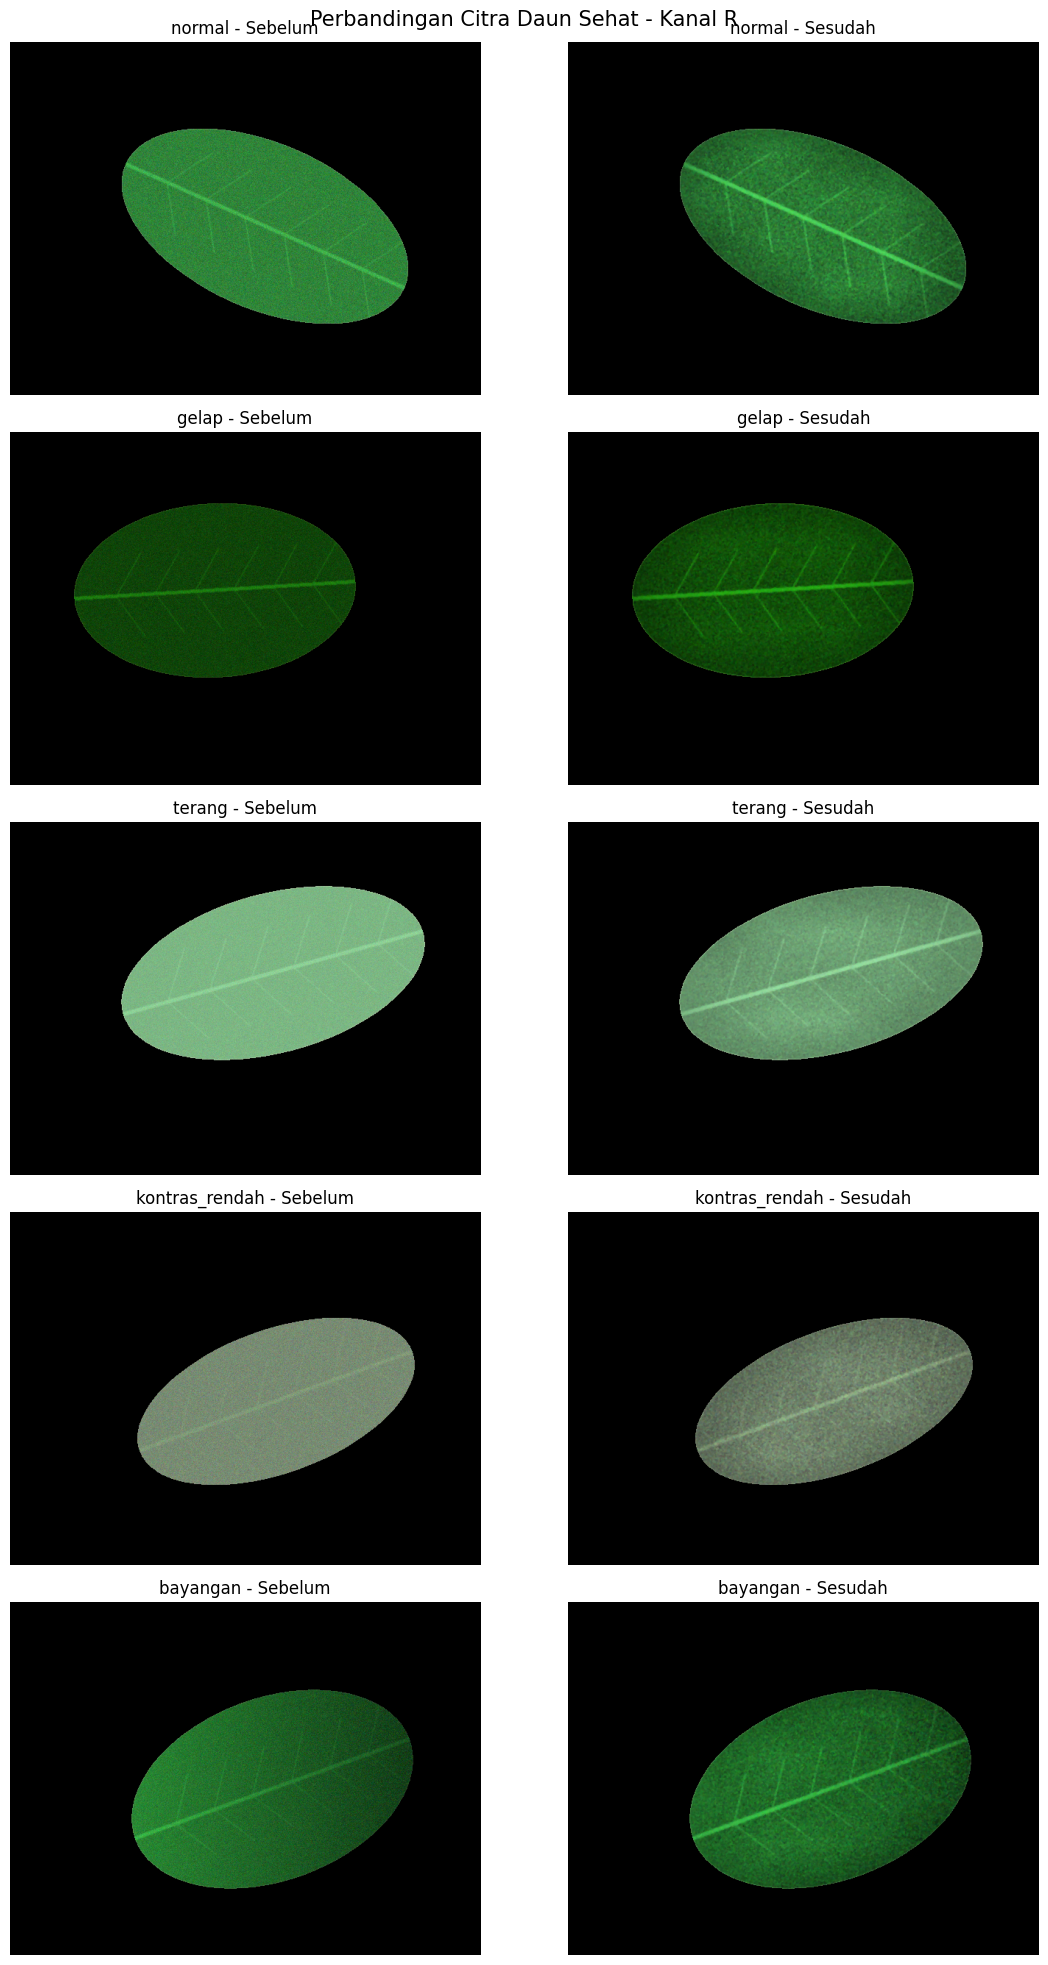

In [ ]:

# ==========================================
# P5.3 - UJI BERCAK PALSU PADA KELAS SEHAT
# ==========================================

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Lokasi proyek
BASE = "/content/drive/MyDrive/simuteh-2330511091"

FOLDER_CITRA = os.path.join(BASE, "data/sintetis/citra")
FOLDER_MASK = os.path.join(BASE, "data/sintetis/mask_daun")
FOLDER_HASIL = os.path.join(BASE, "hasil")

os.makedirs(FOLDER_HASIL, exist_ok=True)

# 2. Import modul praproses
sys.path.insert(0, os.path.join(BASE, "src"))

from praproses import praproses, PARAM_BAWAAN

# 3. Parameter pengujian yang sama untuk semua citra
param = PARAM_BAWAAN.copy()

# Pilih kanal R (OpenCV menggunakan format BGR)
KANAL = 2
NAMA_KANAL = "R"

# Urutan kondisi pencahayaan
urutan = ["normal", "gelap", "terang",
          "kontras_rendah", "bayangan"]

# 4. Baca label dan pilih kelas sehat
label = pd.read_csv(
    os.path.join(BASE, "data/sintetis/label.csv")
)

sehat = label[label["kelas"] == "sehat"].copy()

print("Jumlah citra sehat:", len(sehat))
print("Parameter praproses:", param)

# Pastikan jumlah data sesuai instruksi
assert len(sehat) == 20, "Jumlah citra sehat bukan 20!"

# 5. Proses seluruh citra sehat
baris = []

for _, data in sehat.iterrows():

    nama_file = data["nama_file"]

    # Baca citra dan mask daun
    path_citra = os.path.join(FOLDER_CITRA, nama_file)
    path_mask = os.path.join(FOLDER_MASK, nama_file)

    img = cv2.imread(path_citra)
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path_citra}")

    if mask is None:
        raise FileNotFoundError(f"Mask tidak ditemukan: {path_mask}")

    # Terapkan praproses
    hasil = praproses(img, param)

    # Samakan ukuran citra asli dengan hasil praproses
    tinggi, lebar = hasil.shape[:2]

    img_sebelum = cv2.resize(
        img,
        (lebar, tinggi),
        interpolation=cv2.INTER_AREA
    )

    # Samakan ukuran mask dengan citra hasil
    if mask.shape != (tinggi, lebar):
        mask = cv2.resize(
            mask,
            (lebar, tinggi),
            interpolation=cv2.INTER_NEAREST
        )

    # Area daun
    area_daun = mask > 0

    # Ambil kanal R pada area daun
    sebelum = img_sebelum[:, :, KANAL].astype(np.float32)[area_daun]
    sesudah = hasil[:, :, KANAL].astype(np.float32)[area_daun]

    # Simpangan baku sebelum dan sesudah
    std_sebelum = np.std(sebelum)
    std_sesudah = np.std(sesudah)

    # Ambang titik terang berdasarkan citra sebelum praproses
    batas = sebelum.mean() + 3 * std_sebelum

    persen_terang_sebelum = 100 * np.mean(sebelum > batas)
    persen_terang_sesudah = 100 * np.mean(sesudah > batas)

    # Simpan hasil setiap citra
    baris.append({
        "nama": nama_file,
        "kondisi": data["kondisi_cahaya"],
        "std_sebelum": std_sebelum,
        "std_sesudah": std_sesudah,
        "persen_terang_sebelum": persen_terang_sebelum,
        "persen_terang_sesudah": persen_terang_sesudah
    })

# 6. Buat tabel hasil setiap citra
uji = pd.DataFrame(baris)

print("\nHasil pengujian setiap citra:")
display(uji.round(2))

# 7. Rata-rata berdasarkan kondisi pencahayaan
ringkas = (
    uji.groupby("kondisi")[
        ["std_sebelum", "std_sesudah",
         "persen_terang_sebelum", "persen_terang_sesudah"]
    ]
    .mean()
    .reindex(urutan)
    .round(2)
)

# Hitung persentase perubahan simpangan baku
ringkas["perubahan_std_%"] = (
    (ringkas["std_sesudah"] - ringkas["std_sebelum"])
    / ringkas["std_sebelum"] * 100
).round(2)

print("\nRata-rata berdasarkan kondisi pencahayaan:")
display(ringkas)

# 8. Simpan tabel ke folder hasil
uji.to_csv(
    os.path.join(FOLDER_HASIL, "b5_uji_sehat_per_citra.csv"),
    index=False
)

ringkas.to_csv(
    os.path.join(FOLDER_HASIL, "b5_uji_sehat.csv")
)

print("\nFile CSV berhasil disimpan!")

# 9. Tampilkan panel sebelum dan sesudah
fig, axes = plt.subplots(
    len(urutan), 2,
    figsize=(12, 4 * len(urutan))
)

for i, kondisi in enumerate(urutan):

    # Ambil satu citra untuk setiap kondisi
    data = sehat[sehat["kondisi_cahaya"] == kondisi].iloc[0]

    nama_file = data["nama_file"]

    img = cv2.imread(os.path.join(FOLDER_CITRA, nama_file))
    mask = cv2.imread(
        os.path.join(FOLDER_MASK, nama_file),
        cv2.IMREAD_GRAYSCALE
    )

    hasil = praproses(img, param)

    tinggi, lebar = hasil.shape[:2]

    img_sebelum = cv2.resize(
        img, (lebar, tinggi),
        interpolation=cv2.INTER_AREA
    )

    if mask.shape != (tinggi, lebar):
        mask = cv2.resize(
            mask, (lebar, tinggi),
            interpolation=cv2.INTER_NEAREST
        )

    # Tampilkan area daun saja
    sebelum_rgb = cv2.cvtColor(img_sebelum, cv2.COLOR_BGR2RGB)
    sesudah_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)

    sebelum_tampil = sebelum_rgb.copy()
    sesudah_tampil = sesudah_rgb.copy()

    sebelum_tampil[mask == 0] = 0
    sesudah_tampil[mask == 0] = 0

    axes[i, 0].imshow(sebelum_tampil)
    axes[i, 0].set_title(f"{kondisi} - Sebelum")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(sesudah_tampil)
    axes[i, 1].set_title(f"{kondisi} - Sesudah")
    axes[i, 1].axis("off")

plt.suptitle(
    f"Perbandingan Citra Daun Sehat - Kanal {NAMA_KANAL}",
    fontsize=15
)

plt.tight_layout()
plt.show()
